# Coinbase Data Breach (May 15, 2025): Effect on Stock Returns

**Question:** Did the breach disclosure lower Coinbase's (COIN) stock return compared with similar companies?

**Approach:** Show the price and return trends, then use a simple one-day model: on May 15, compare COIN's return with the average of its crypto and fintech peers. A placebo test checks whether that gap is unusual.

**Sections**
1. Setup
2. Bronze: download raw prices
3. Data checks
4. Silver: clean daily returns
5. Trends (exploratory plots)
6. One-day model: COIN vs. peers on May 15
7. Validation (placebo tests)

## 1. Setup

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import yfinance as yf
from pathlib import Path

print(sys.executable)
print("yfinance", yf.__version__)

/usr/local/Caskroom/miniconda/base/envs/datasci200/bin/python
yfinance 1.7.0


In [2]:
START, END = "2023-05-01", "2026-03-30"
EVENT_DATE = pd.Timestamp("2025-05-15")   # breach disclosed

# tickers grouped by why they're in the study
TICKERS = {
    "target":      ["COIN"],                       # Coinbase
    "crypto":      ["BTC-USD", "ETH-USD"],          # Bitcoin, Ethereum prices
    "market":      ["SPY", "QQQ", "^VIX"],          # S&P 500, Nasdaq, market fear index
    "crypto_peer": ["HOOD", "MSTR", "MARA", "RIOT"],# Robinhood, MicroStrategy, BTC miners
    "fintech_peer":["PYPL", "XYZ", "IBKR", "SCHW"], # PayPal, Block, Interactive Brokers, Schwab
}
all_tickers = [t for group in TICKERS.values() for t in group]
peers = TICKERS["crypto_peer"] + TICKERS["fintech_peer"]

for layer in ["bronze", "silver"]:
    Path(f"data/{layer}").mkdir(parents=True, exist_ok=True)

## 2. Bronze: download raw prices

In [3]:
raw = yf.download(all_tickers, start=START, end=END, auto_adjust=True, progress=False)
print(raw.shape)
raw.head()

(1064, 70)


Price              Close                                                  \
Ticker           BTC-USD       COIN      ETH-USD  HOOD       IBKR   MARA   
Date                                                                       
2023-05-01  28091.568359  50.139999  1831.954834  8.82  18.948971   8.78   
2023-05-02  28680.537109  51.320000  1870.789307  8.46  18.200144   9.55   
2023-05-03  29006.308594  48.490002  1904.651855  8.38  17.812231   9.55   
2023-05-04  28847.710938  49.220001  1877.704102  8.48  17.532343  10.27   
2023-05-05  29534.384766  58.240002  1995.060913  8.85  18.794296  10.49   

Price                                                ...     Volume  \
Ticker           MSTR       PYPL         QQQ   RIOT  ...       IBKR   
Date                                                 ...              
2023-05-01  30.747000  74.281616  315.897949  10.52  ...  4423200.0   
2023-05-02  32.800999  71.482826  313.142792  11.78  ...  3654400.0   
2023-05-03  30.424999  70.642212  311.093628  10.74  ...  4781200.0   
2023-05-04  31.224001  71.018013  309.995514  10.84  ...  4281600.0   
2023-05-05  32.672001  74.143166  316.584259  11.54  ...  6241200.0   

Price                                                                   \
Ticker            MARA        MSTR        PYPL         QQQ        RIOT   
Date                                                                     
2023-05-01  28506300.0   9055000.0   6857900.0  41013400.0  19192300.0   
2023-05-02  32177300.0  13733000.0  12767000.0  56519400.0  22935300.0   
2023-05-03  26882400.0  11930000.0  11865700.0  59882100.0  27764600.0   
2023-05-04  35765100.0   7151000.0  10230500.0  50224500.0  23478600.0   
2023-05-05  37753400.0   9082000.0  11954200.0  51806100.0  28585500.0   

Price                                                 
Ticker            SCHW          SPY         XYZ ^VIX  
Date                                                  
2023-05-01  11041000.0   62122300.0   9293600.0  0.0  
2023-05-02  20934400.0  103998500.0  10440300.0  0.0  
2023-05-03  22505400.0   91531800.0  14798400.0  0.0  
2023-05-04  26316200.0   94901900.0  16023900.0  0.0  
2023-05-05  22019600.0   87891800.0  25485600.0  0.0  

[5 rows x 70 columns]

In [4]:
# reshape to "long" format: one row per ticker per day
long = (raw[["Close", "Volume"]]
        .stack(level=1)
        .reset_index()
        .rename(columns={"Date": "date", "Ticker": "ticker",
                         "Close": "close", "Volume": "volume"}))
long["date"] = pd.to_datetime(long["date"])

# add group label
group_of = {t: g for g, ts in TICKERS.items() for t in ts}
long["group"] = long["ticker"].map(group_of)

long.to_csv("data/bronze/yahoo_prices.csv", index=False)
long.head()

Price,date,ticker,close,volume,group
0,2023-05-01,BTC-USD,28091.568359,1.865560e+10,crypto
1,2023-05-01,COIN,50.139999,1.843790e+07,target
2,2023-05-01,ETH-USD,1831.954834,8.625783e+09,crypto
3,2023-05-01,HOOD,8.820000,6.564000e+06,crypto_peer
4,2023-05-01,IBKR,18.948971,4.423200e+06,fintech_peer


## 3. Data checks

In [5]:
print("Start:", raw.index.min())
print("End:  ", raw.index.max())
print("Number of days:", len(raw))

Start: 2023-05-01 00:00:00
End:   2026-03-29 00:00:00
Number of days: 1064


In [6]:
# Did every ticker download? Check the date range and row counts.
# Stocks ~250 rows/year, BTC/ETH ~365 (crypto trades every day).
long.groupby("ticker").agg(first=("date", "min"),
                           last=("date", "max"),
                           rows=("close", "count"))

,first,last,rows
ticker,,,
BTC-USD,2023-05-01,2026-03-29,1064
COIN,2023-05-01,2026-03-29,730
ETH-USD,2023-05-01,2026-03-29,1064
HOOD,2023-05-01,2026-03-29,730
IBKR,2023-05-01,2026-03-29,730
MARA,2023-05-01,2026-03-29,730
MSTR,2023-05-01,2026-03-29,730
PYPL,2023-05-01,2026-03-29,730
QQQ,2023-05-01,2026-03-29,730


In [7]:
long.describe()

Price,date,close,volume
count,14896,10888.000000,1.088800e+04
mean,2024-10-13 12:00:00,7327.796053,5.712860e+09
min,2023-05-01 00:00:00,6.290000,0.000000e+00
25%,2024-01-21 18:00:00,26.412323,8.060975e+06
50%,2024-10-13 12:00:00,77.349998,2.046670e+07
75%,2025-07-06 06:00:00,535.835770,6.703665e+07
max,2026-03-29 00:00:00,124752.531250,1.817464e+11
std,NaN,22857.983776,1.506857e+10


## 4. Silver: clean daily returns
Keep only days the stock market was open (drops BTC/ETH weekend rows), so every ticker's return covers the same period.

In [8]:
long = long.dropna(subset=["close"])   # drop empty rows (stocks have no price on weekends)

trading_days = long.loc[long["ticker"] == "COIN", "date"].unique()
long = long[long["date"].isin(trading_days)]

long = long.sort_values(["ticker", "date"])
long["return_pct"] = long.groupby("ticker")["close"].pct_change() * 100

long.to_csv("data/silver/yahoo_returns.csv", index=False)
long[(long["ticker"] == "COIN") & (long["date"].between("2025-05-12", "2025-05-16"))]

Price,date,ticker,close,volume,group,return_pct
10389,2025-05-12,COIN,207.220001,14944200.0,target,3.963473
10403,2025-05-13,COIN,256.899994,39119000.0,target,23.974516
10417,2025-05-14,COIN,263.410004,18344700.0,target,2.534064
10431,2025-05-15,COIN,244.440002,25917200.0,target,-7.201701
10445,2025-05-16,COIN,266.459991,72627500.0,target,9.008341


In [9]:
coin_ret = long.loc[(long["ticker"] == "COIN") & (long["date"] == EVENT_DATE), "return_pct"].item()
print(f"COIN return on May 15: {coin_ret:.2f}%")

COIN return on May 15: -7.20%


## 5. Trends (exploratory plots)

### Close price, one chart per ticker

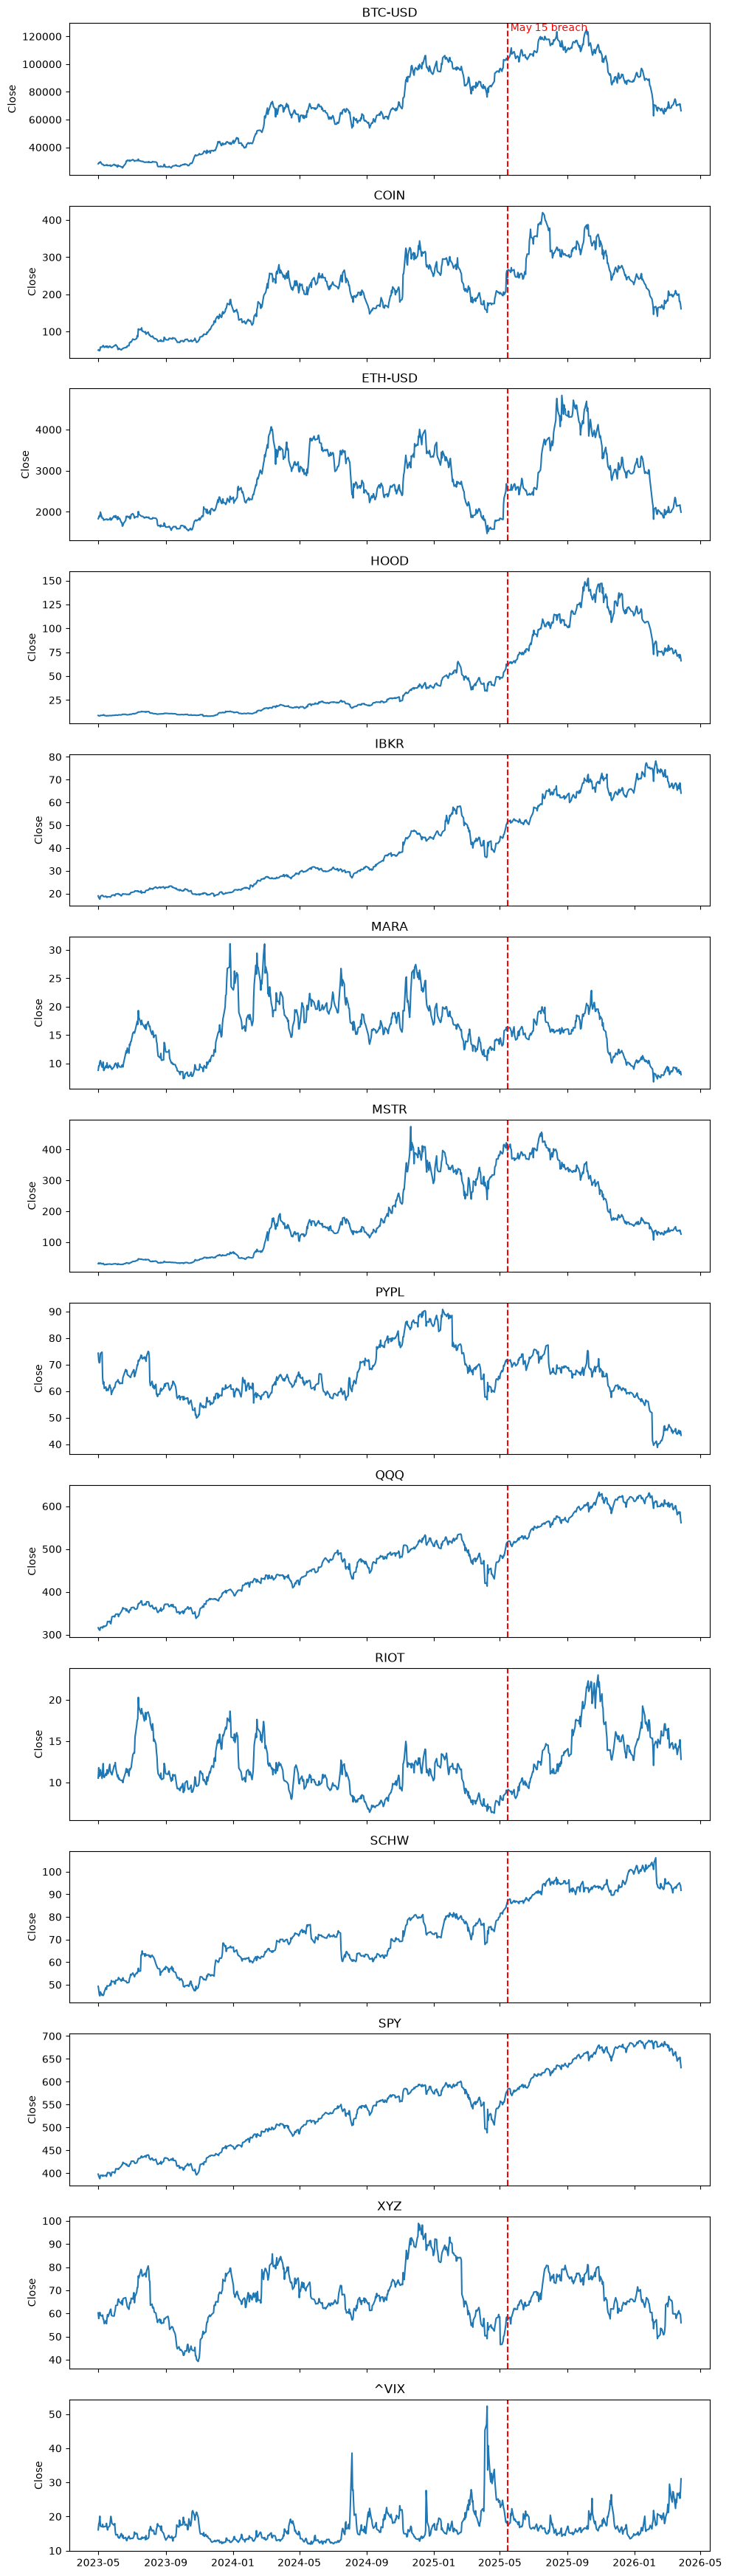

In [10]:
tickers = long["ticker"].unique()
fig, axes = plt.subplots(len(tickers), 1, figsize=(10, 2.5 * len(tickers)), sharex=True)

for ax, t in zip(axes, tickers):
    d = long[long["ticker"] == t]
    ax.plot(d["date"], d["close"])
    ax.axvline(EVENT_DATE, color="red", linestyle="--")   # breach disclosed
    ax.set_title(t)
    ax.set_ylabel("Close")

axes[0].text(EVENT_DATE, axes[0].get_ylim()[1], " May 15 breach", color="red", va="top")
plt.tight_layout()
plt.show()

### Price index around the event (April 1 = 100)
A line at 120 means the price is 20% higher than on April 1; 90 means 10% lower.

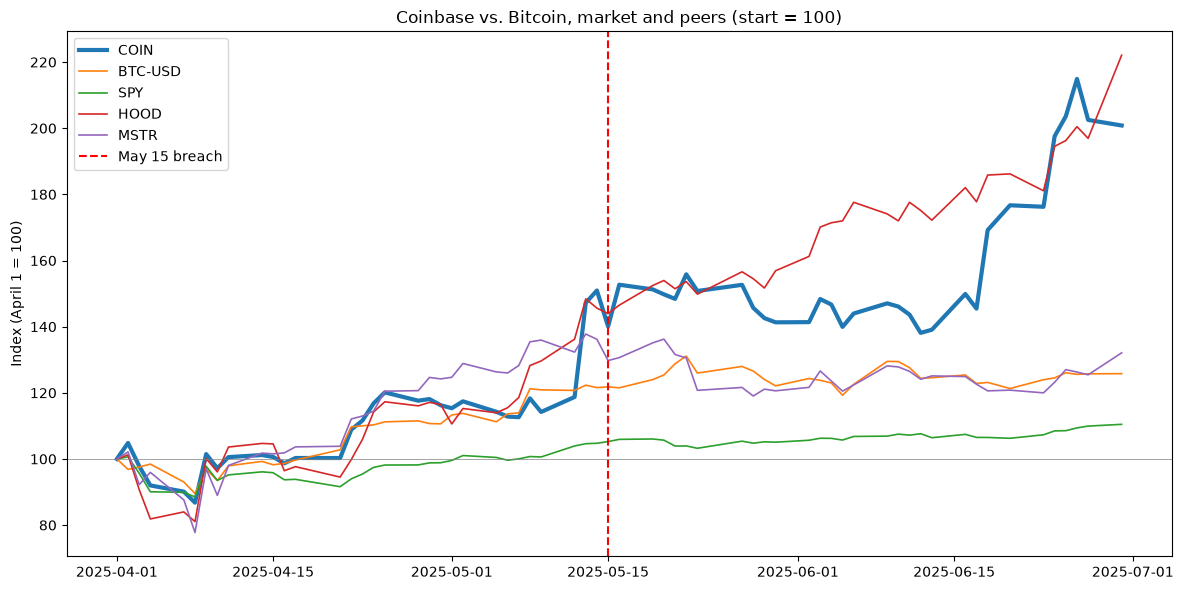

In [11]:
# one column per ticker, zoomed in around the event
wide = long.pivot(index="date", columns="ticker", values="close")
wide = wide.loc["2025-04-01":"2025-06-30"]

# rescale: every line starts at 100
norm = wide / wide.iloc[0] * 100

show = ["COIN", "BTC-USD", "SPY", "HOOD", "MSTR"]

plt.figure(figsize=(12, 6))
for t in show:
    plt.plot(norm.index, norm[t], label=t,
             linewidth=3 if t == "COIN" else 1.2)

plt.axvline(EVENT_DATE, color="red", linestyle="--", label="May 15 breach")
plt.axhline(100, color="gray", linewidth=0.5)
plt.title("Coinbase vs. Bitcoin, market and peers (start = 100)")
plt.ylabel("Index (April 1 = 100)")
plt.legend()
plt.tight_layout()
plt.show()

### Daily returns around the event

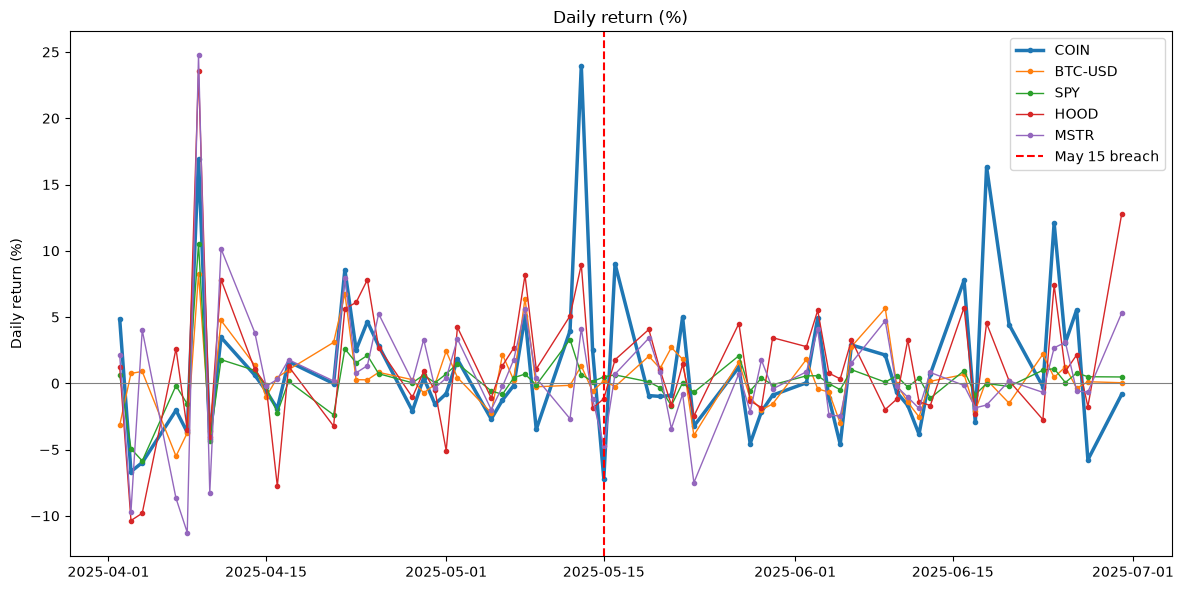

In [12]:
ret = wide.pct_change() * 100
ret = ret.dropna(how="all")      # first row is empty (no previous day)

plt.figure(figsize=(12, 6))
for t in show:
    plt.plot(ret.index, ret[t], label=t,
             linewidth=2.5 if t == "COIN" else 1, marker="o", markersize=3)

plt.axvline(EVENT_DATE, color="red", linestyle="--", label="May 15 breach")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Daily return (%)")
plt.ylabel("Daily return (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [13]:
# returns for every ticker in the days around the event
ret.loc["2025-05-08":"2025-05-22"].round(2)

ticker,BTC-USD,COIN,ETH-USD,HOOD,IBKR,MARA,MSTR,PYPL,QQQ,RIOT,SCHW,SPY,XYZ,^VIX
date,,,,,,,,,,,,,,
2025-05-08,6.40,5.06,21.80,8.16,2.61,7.20,5.58,2.61,1.03,7.65,0.43,0.70,4.50,-4.54
2025-05-09,-0.26,-3.48,6.30,1.07,0.60,10.29,0.40,-0.31,-0.07,0.47,0.44,-0.13,0.50,-2.58
2025-05-12,-0.15,3.96,6.43,5.09,6.27,1.21,-2.68,2.92,4.07,2.59,1.07,3.30,9.25,-16.03
2025-05-13,1.32,23.97,7.36,8.95,2.81,2.63,4.13,-0.03,1.52,4.14,1.00,0.66,5.73,-0.92
2025-05-14,-0.61,2.53,-2.61,-1.89,0.36,-3.05,-1.15,0.54,0.60,-1.66,1.09,0.13,0.57,2.20
2025-05-15,0.20,-7.20,-2.42,-1.16,1.72,-1.20,-4.73,-1.53,0.11,-2.36,1.09,0.49,-2.55,-4.24
2025-05-16,-0.25,9.01,-0.41,1.78,1.04,3.38,0.70,0.85,0.44,5.17,0.66,0.63,1.14,-3.31
2025-05-19,2.05,-0.93,-0.28,4.06,-0.55,0.68,3.41,0.19,0.10,-1.97,0.61,0.11,1.16,5.22
2025-05-20,1.12,-0.99,-0.20,1.00,1.12,-0.80,0.85,0.40,-0.33,-0.45,-0.06,-0.34,-1.70,-0.28


## 6. One-day model: COIN vs. peers on May 15
Use only May 15 data (COIN + 8 peers) and run `return_pct ~ treated`.
- `Intercept` = the peers' average return that day
- `treated` = COIN's return **minus** the peer average (the breach-day gap)

In [14]:
event = long[long["ticker"].isin(["COIN"] + peers) & (long["date"] == EVENT_DATE)].copy()
event["treated"] = (event["ticker"] == "COIN").astype(int)

event[["ticker", "return_pct"]].sort_values("return_pct").round({"return_pct": 2})

Price,ticker,return_pct
10431,COIN,-7.20
10436,MSTR,-4.73
10442,XYZ,-2.55
10439,RIOT,-2.36
10437,PYPL,-1.53
10435,MARA,-1.20
10433,HOOD,-1.16
10440,SCHW,1.09
10434,IBKR,1.72


In [15]:
model = smf.ols("return_pct ~ treated", data=event).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             return_pct   R-squared:                       0.510
Model:                            OLS   Adj. R-squared:                  0.440
Method:                 Least Squares   F-statistic:                     7.294
Date:                Thu, 01 Oct 2026   Prob (F-statistic):             0.0306
Time:                        14:11:46   Log-Likelihood:                -18.086
No. Observations:                   9   AIC:                             40.17
Df Residuals:                       7   BIC:                             40.57
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.3390      0.724     -1.850      0.1

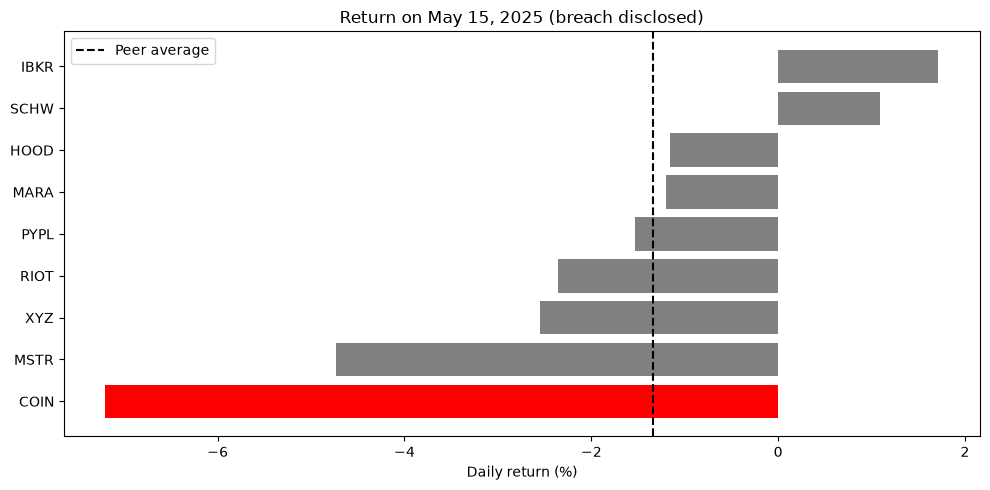

In [16]:
# bar chart of the event-day returns
d = event.sort_values("return_pct")
colors = ["red" if t == "COIN" else "gray" for t in d["ticker"]]

plt.figure(figsize=(10, 5))
plt.barh(d["ticker"], d["return_pct"], color=colors)
plt.axvline(d.loc[d["treated"] == 0, "return_pct"].mean(), color="black", linestyle="--",
            label="Peer average")
plt.title("Return on May 15, 2025 (breach disclosed)")
plt.xlabel("Daily return (%)")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Validation (placebo tests)
With only one COIN observation, the p-value above is rough. Instead, run the **same one-day model on ordinary days**:
if COIN often differs from its peers by this much on normal days, the May 15 gap is not special.

In [17]:
data = long[long["ticker"].isin(["COIN"] + peers)].dropna(subset=["return_pct"]).copy()

# the same one-day model, for any date
def day_effect(data, date, treated="COIN"):
    d = data[data["date"] == date].copy()
    d["treated"] = (d["ticker"] == treated).astype(int)
    m = smf.ols("return_pct ~ treated", data=d).fit()
    return m.params["treated"]       # = COIN return minus peer average that day

trading_days = pd.DatetimeIndex(sorted(data["date"].unique()))
event_pos = trading_days.get_loc(EVENT_DATE)
real = day_effect(data, EVENT_DATE)

### Placebo 1: the day before

In [18]:
placebo_date = trading_days[event_pos - 1]     # previous trading day (May 14)

print("Real effect    (", EVENT_DATE.date(), "):", round(real, 2))
print("Placebo effect (", placebo_date.date(), "):", round(day_effect(data, placebo_date), 2))

Real effect    ( 2025-05-15 ): -5.86
Placebo effect ( 2025-05-14 ): 3.18


### Placebo 2: 60 ordinary days before the event
Skips May 13–14 (S&P 500 inclusion news). The share of fake days with a gap at least as large as May 15 works like a p-value.

Mean placebo effect: -0.43  (should be close to 0)
Real effect: -5.86
Share of placebo days at least as extreme: 3.33%


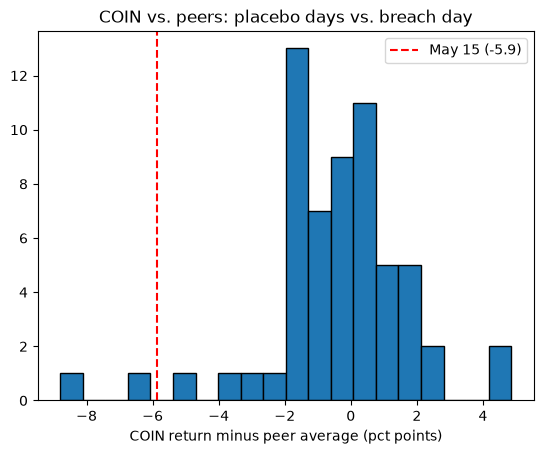

In [19]:
placebo_days = trading_days[trading_days < "2025-05-13"][-60:]
placebo = pd.Series({d: day_effect(data, d) for d in placebo_days})

print(f"Mean placebo effect: {placebo.mean():.2f}  (should be close to 0)")
print(f"Real effect: {real:.2f}")
print(f"Share of placebo days at least as extreme: {(placebo.abs() >= abs(real)).mean():.2%}")

plt.hist(placebo, bins=20, edgecolor="black")
plt.axvline(real, color="red", linestyle="--", label=f"May 15 ({real:.1f})")
plt.title("COIN vs. peers: placebo days vs. breach day")
plt.xlabel("COIN return minus peer average (pct points)")
plt.legend()
plt.show()